In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

model_name = "openai/clip-vit-base-patch16"  # or patch32, large-patch14, etc.
model = CLIPModel.from_pretrained(model_name).eval()
processor = CLIPProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    vision_outputs = model.vision_model(
        pixel_values=inputs["pixel_values"],
        output_hidden_states=True,
    )

# last_hidden_state: [batch, 1 + num_patches, hidden_dim]
# token 0 = CLS, tokens 1: = patch tokens (pre-pooling, pre-projection)
last_hidden = vision_outputs.last_hidden_state
cls_token = last_hidden[:, 0, :]
patch_tokens = last_hidden[:, 1:, :]   # dense features, shape [B, N, D]

# reshape to spatial grid
B, N, D = patch_tokens.shape
grid_size = int(N ** 0.5)              # e.g. 14 for a 224px/16px-patch model
dense_features = patch_tokens.reshape(B, grid_size, grid_size, D).permute(0, 3, 1, 2)
# dense_features: [B, D, H, W] — spatial dense feature map

print(dense_features.shape)

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

torch.Size([1, 768, 14, 14])


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

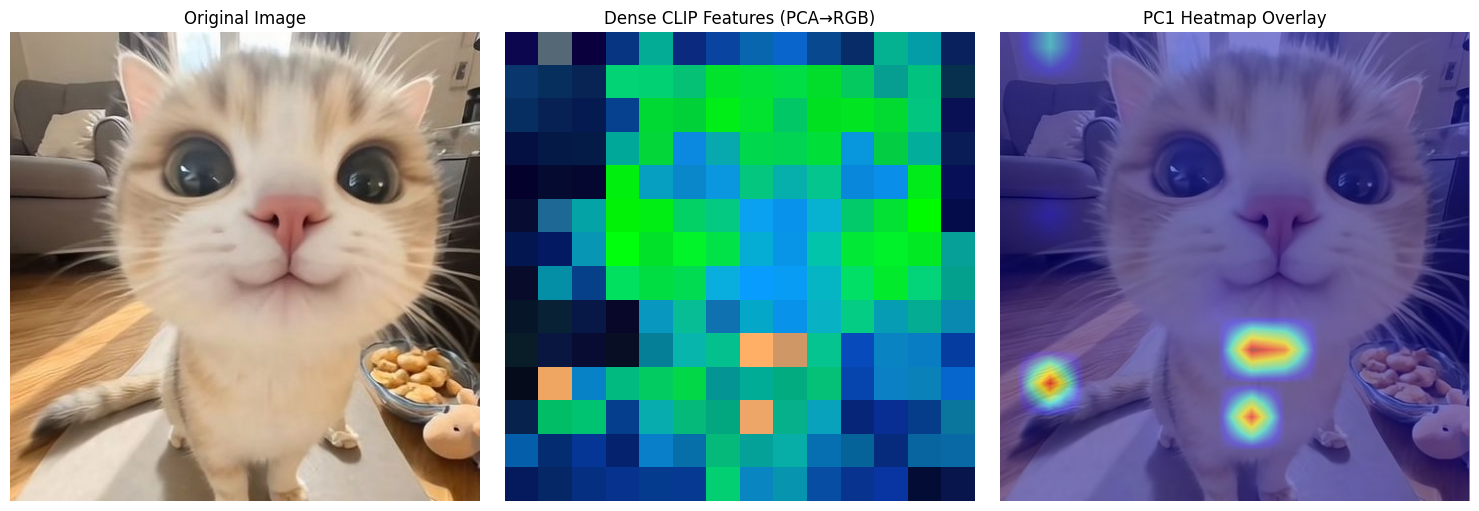

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

# --- 1. Extract dense features (from Option 1) ---
model_name = "openai/clip-vit-base-patch16"
model = CLIPModel.from_pretrained(model_name).eval()
processor = CLIPProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    vision_outputs = model.vision_model(
        pixel_values=inputs["pixel_values"],
        output_hidden_states=True,
    )

last_hidden = vision_outputs.last_hidden_state
patch_tokens = last_hidden[:, 1:, :]        # [1, N, D]
B, N, D = patch_tokens.shape
grid_size = int(N ** 0.5)                    # e.g. 14

patch_tokens_np = patch_tokens[0].numpy()    # [N, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(patch_tokens_np)   # [N, 3]

# normalize each component to [0, 1] for display
pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_size, grid_size, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense CLIP Features (PCA→RGB)")
axes[1].axis("off")

# single top PCA component as a heatmap, upsampled to image resolution
pca1 = pca_features_norm[:, 0].reshape(grid_size, grid_size)
axes[2].imshow(image)
axes[2].imshow(
    pca1, cmap="jet", alpha=0.5,
    extent=(0, image.width, image.height, 0),  # stretch grid over original image
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("clip_dense_features.png", dpi=150)
plt.show()